<a href="https://colab.research.google.com/github/sriraksha-Prabhu/APS/blob/main/APS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix


In [ ]:
data=load_breast_cancer()
x=pd.DataFrame(data.data,columns=data.feature_names)
y=pd.Series((data.target==0).astype(int),name="malignant")
print(y.value_counts())
print("feature matrix shape",x.shape)
print("Target shape",y.shape)
print("Class names",data.target_names)

malignant
0    357
1    212
Name: count, dtype: int64
feature matrix shape (569, 30)
Target shape (569,)
Class names ['malignant' 'benign']


In [ ]:
class_counts=y.value_counts().sort_index()
class_distribution=pd.DataFrame({
    "Class":data.target_names,
    "Count":class_counts.values,
    "Probability":class_counts.values/len(y)
})
print(class_distribution)

       Class  Count  Probability
0  malignant    357     0.627417
1     benign    212     0.372583


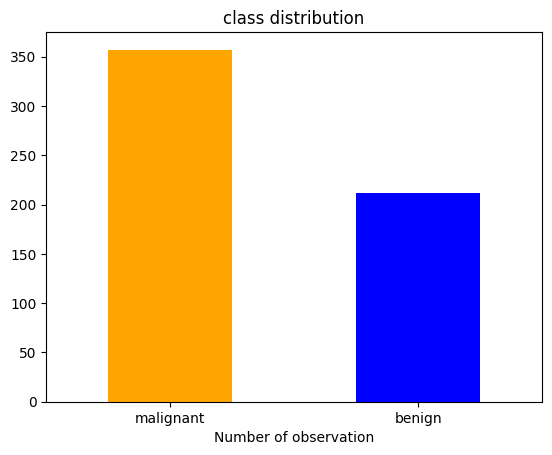

In [ ]:
class_distribution.plot(
    x="Class",
    y="Count",
    kind="bar",
    legend=False,
    color=["orange","blue"]

)

plt.xlabel("Number of observation")
plt.title("class distribution")
plt.xticks(rotation=0)
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training size:", len(y_train))
print("Testing size:", len(y_test))

print("\nTraining proportion:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting proportion:")
print(y_test.value_counts(normalize=True).sort_index())


Training size: 455
Testing size: 114

Training proportion:
malignant
0    0.626374
1    0.373626
Name: proportion, dtype: float64

Testing proportion:
malignant
0    0.631579
1    0.368421
Name: proportion, dtype: float64


In [ ]:
model=make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
model.fit(X_train,y_train)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [ ]:
probabilities=model.predict_proba(X_test)
print(probabilities[:5])

[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]


In [ ]:
print(probabilities[:5].sum(axis=1))

[1. 1. 1. 1. 1.]


In [ ]:
results=pd.DataFrame({
    "Actual Class":y_test.values,
    "P_malignant":probabilities[:,0],
    "P_benign":probabilities[:,1]
})
print(results.head(10))

   Actual Class   P_malignant  P_benign
0             0  9.996354e-01  0.000365
1             1  1.074660e-08  1.000000
2             0  9.574321e-01  0.042568
3             1  4.238127e-01  0.576187
4             0  4.908445e-01  0.509155
5             0  9.993840e-01  0.000616
6             1  2.384659e-01  0.761534
7             0  9.989878e-01  0.001012
8             0  9.994313e-01  0.000569
9             0  9.892324e-01  0.010768


In [ ]:
thresold=0.50
results["predicted_malignant"]=(
    results["P_malignant"]>=thresold

).astype(int)

results["Predicted_label"]=results[
    "predicted_malignant"
].map({
    0:"Malignant",
    1:"Benign"
})

print(
    results[
        [
        "Actual Class",
        "P_malignant",
        "Predicted_label"
    ]
    ]
)


     Actual Class   P_malignant Predicted_label
0               0  9.996354e-01          Benign
1               1  1.074660e-08       Malignant
2               0  9.574321e-01          Benign
3               1  4.238127e-01       Malignant
4               0  4.908445e-01       Malignant
..            ...           ...             ...
109             0  9.998799e-01          Benign
110             0  9.996350e-01          Benign
111             0  8.844442e-01          Benign
112             1  5.083901e-01          Benign
113             1  7.446726e-04       Malignant

[114 rows x 3 columns]


In [ ]:
for thresold in [0.30, 0.50,0.70]:
    predictions=(
        results["P_malignant"]>=threshold
    ).astype(int)

    print(
        f"thersold={threshold}:"
        f"Predicted malignant cases={predictions.sum()}"
    )

thersold=0.5:Predicted malignant cases=74
thersold=0.5:Predicted malignant cases=74
thersold=0.5:Predicted malignant cases=74


In [ ]:
actual_malignant=(y_test.values==0).astype(int)

for thresold in [0.30, 0.50,0.70]:
    predictions_malignant=(
        probabilities[:,0]>=threshold
    ).astype(int)

    cm=confusion_matrix(
        actual_malignant,
        predictions_malignant
    )

    print(f"theresold={threshold}")
    print(cm)

theresold=0.5
[[39  3]
 [ 1 71]]
theresold=0.5
[[39  3]
 [ 1 71]]
theresold=0.5
[[39  3]
 [ 1 71]]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_pred = model.predict(X_test)

print(
    "sklearn accuracy:",
    accuracy_score(y_test, y_pred)
)

print(
    "sklearn precision:",
    precision_score(y_test, y_pred)
)

print(
    "sklearn recall/sensitivity:",
    recall_score(y_test, y_pred)
)

print(
    "sklearn f1 score:",
    f1_score(y_test, y_pred)
)

sklearn accuracy: 0.9649122807017544
sklearn precision: 0.975
sklearn recall/sensitivity: 0.9285714285714286
sklearn f1 score: 0.9512195121951219


In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd

metric_results = []

for threshold in [0.10, 0.30, 0.50, 0.70, 0.90]:

    y_pred_threshold = (
        probabilities[:, 1] >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=[0, 1]
    ).ravel()

    accuracy = (tp + tn) / (tp + tn + fp + fn)

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    f1 = (
        2 * precision * sensitivity /
        (precision + sensitivity)
        if (precision + sensitivity) > 0
        else 0
    )

    metric_results.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity_Recall": sensitivity,
        "Specificity": specificity,
        "F1_Score": f1
    })

threshold_metrics = pd.DataFrame(metric_results)

display(
    threshold_metrics.round(3)
)

,Threshold,TN,FP,FN,TP,Accuracy,Precision,Sensitivity_Recall,Specificity,F1_Score
0,0.1,67,5,1,41,0.947,0.891,0.976,0.931,0.932
1,0.3,71,1,1,41,0.982,0.976,0.976,0.986,0.976
2,0.5,71,1,3,39,0.965,0.975,0.929,0.986,0.951
3,0.7,72,0,4,38,0.965,1.000,0.905,1.000,0.950
4,0.9,72,0,9,33,0.921,1.000,0.786,1.000,0.880
